
=== Fold 1 ===


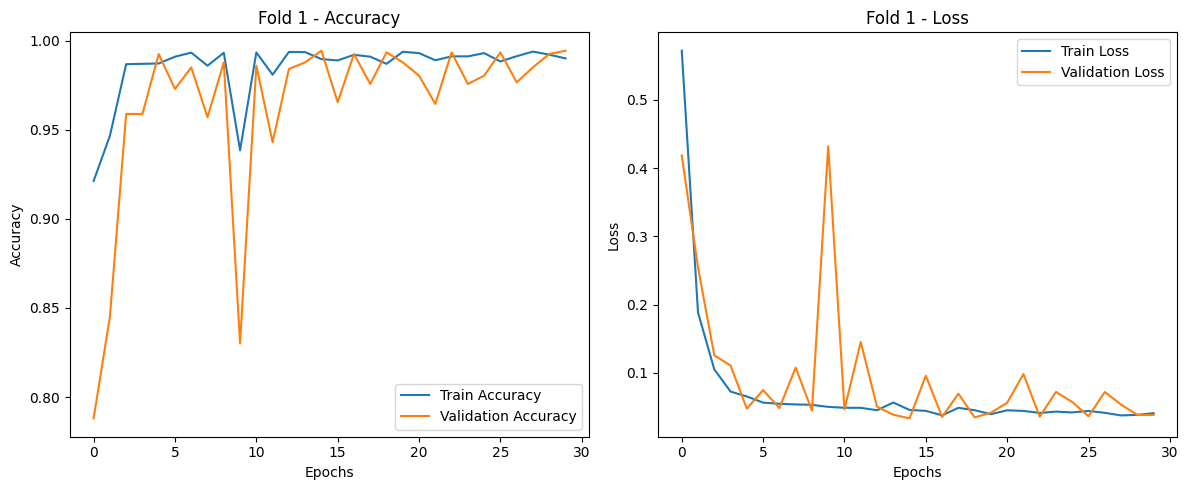

Fold 1 Accuracy: 0.9944 | Macro F1: 0.9902

Class 0 -> Precision: 0.9954, Recall: 0.9977, F1: 0.9966
Class 1 -> Precision: 0.9825, Recall: 0.9655, F1: 0.9739
Class 3 -> Precision: 1.0000, Recall: 1.0000, F1: 1.0000


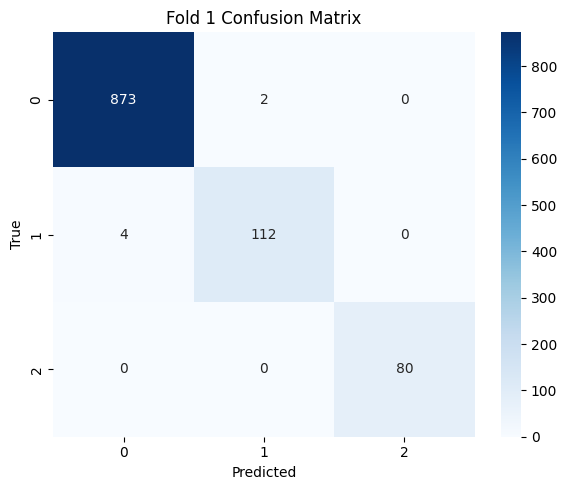


=== Fold 2 ===


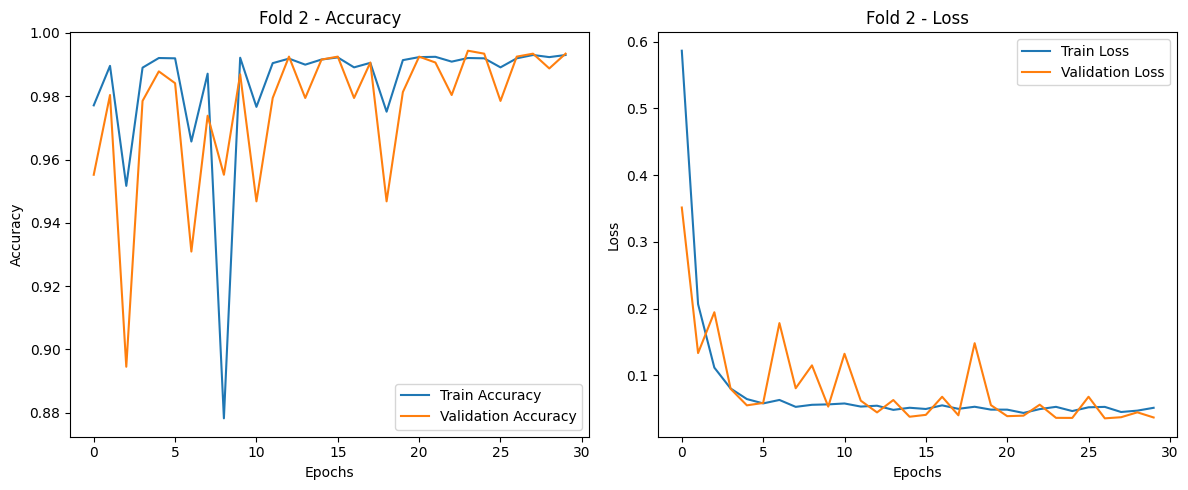

Fold 2 Accuracy: 0.9935 | Macro F1: 0.9888

Class 0 -> Precision: 0.9989, Recall: 0.9931, F1: 0.9960
Class 1 -> Precision: 0.9504, Recall: 0.9914, F1: 0.9705
Class 3 -> Precision: 1.0000, Recall: 1.0000, F1: 1.0000


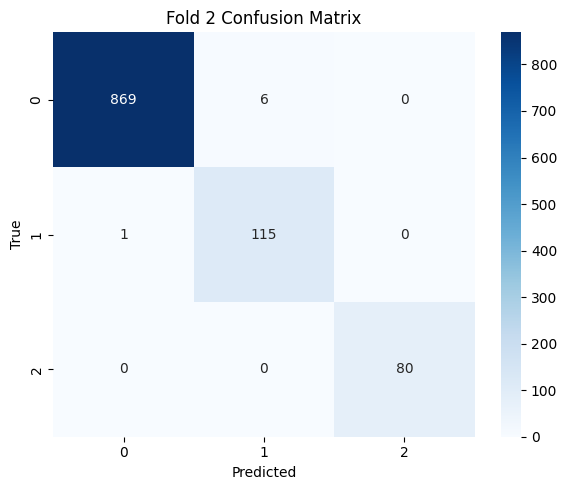


=== Fold 3 ===


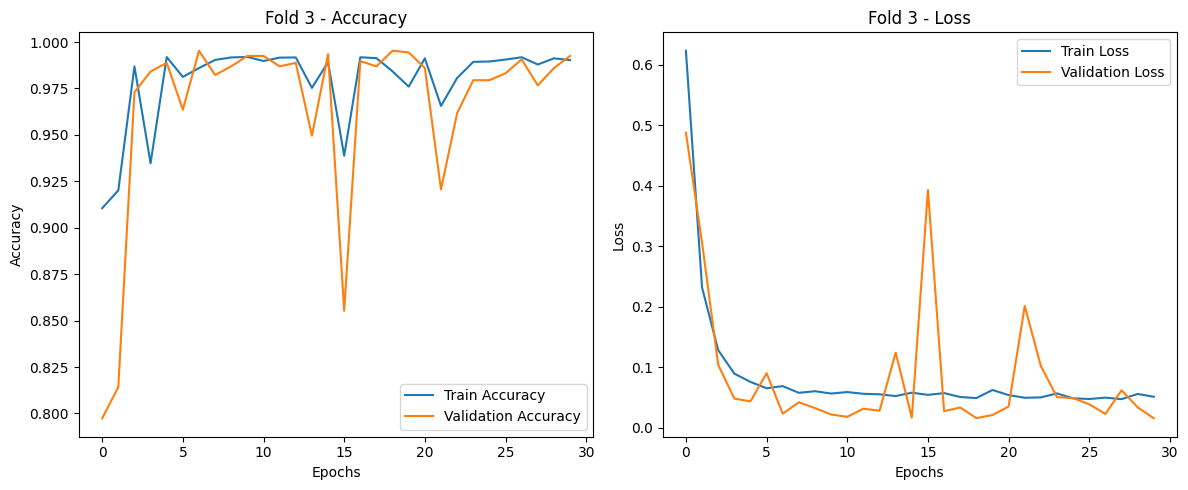

Fold 3 Accuracy: 0.9925 | Macro F1: 0.9873

Class 0 -> Precision: 0.9977, Recall: 0.9931, F1: 0.9954
Class 1 -> Precision: 0.9504, Recall: 0.9829, F1: 0.9664
Class 3 -> Precision: 1.0000, Recall: 1.0000, F1: 1.0000


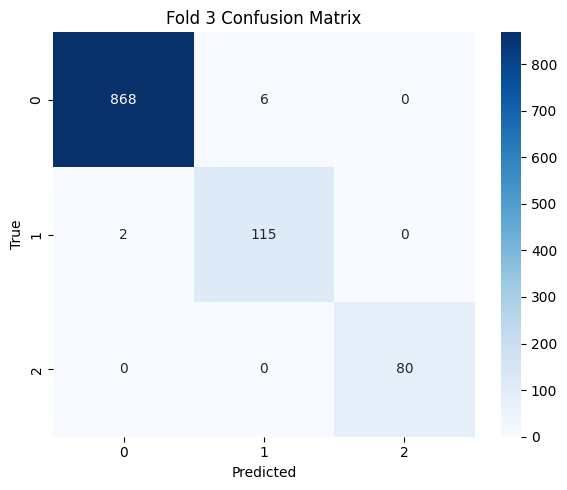


=== Fold 4 ===


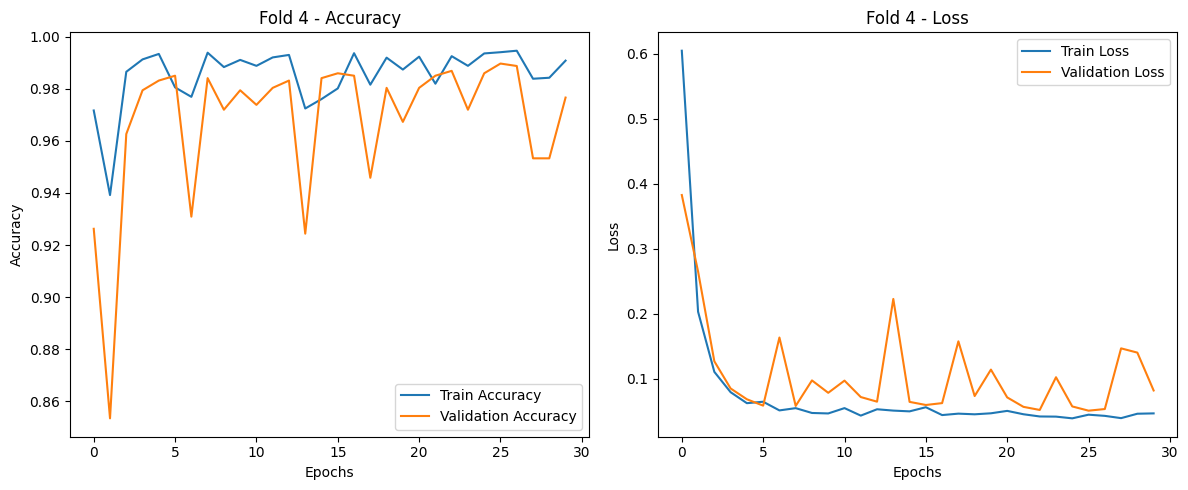

Fold 4 Accuracy: 0.9767 | Macro F1: 0.9630

Class 0 -> Precision: 1.0000, Recall: 0.9714, F1: 0.9855
Class 1 -> Precision: 0.8239, Recall: 1.0000, F1: 0.9035
Class 3 -> Precision: 1.0000, Recall: 1.0000, F1: 1.0000


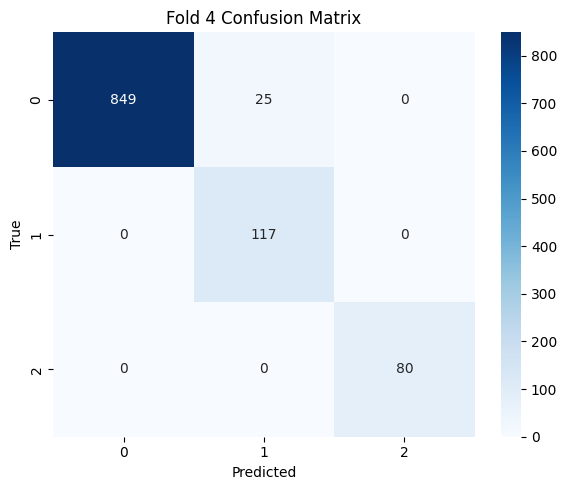


=== Fold 5 ===


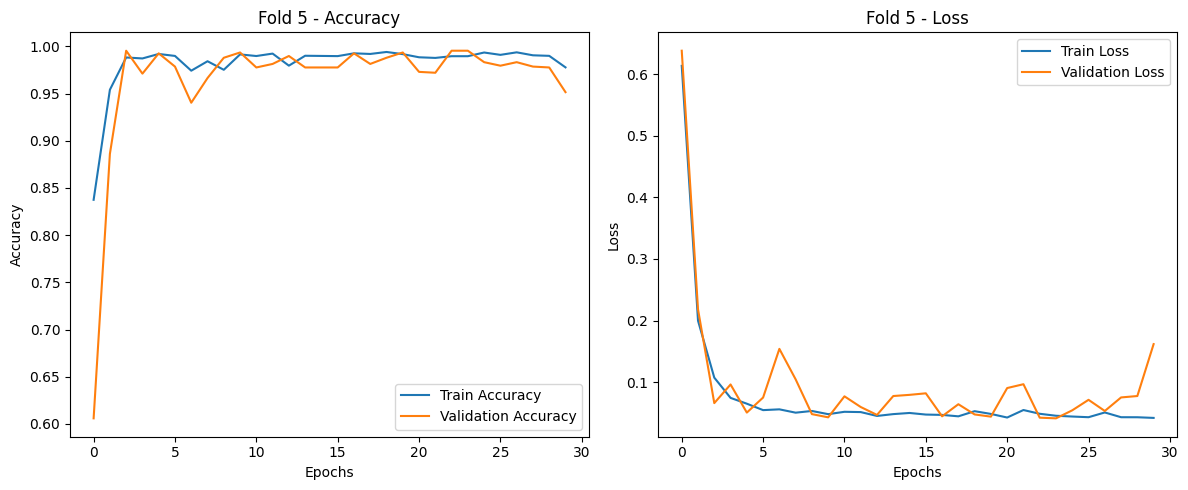

Fold 5 Accuracy: 0.9514 | Macro F1: 0.9292

Class 0 -> Precision: 1.0000, Recall: 0.9405, F1: 0.9693
Class 1 -> Precision: 0.6923, Recall: 1.0000, F1: 0.8182
Class 3 -> Precision: 1.0000, Recall: 1.0000, F1: 1.0000


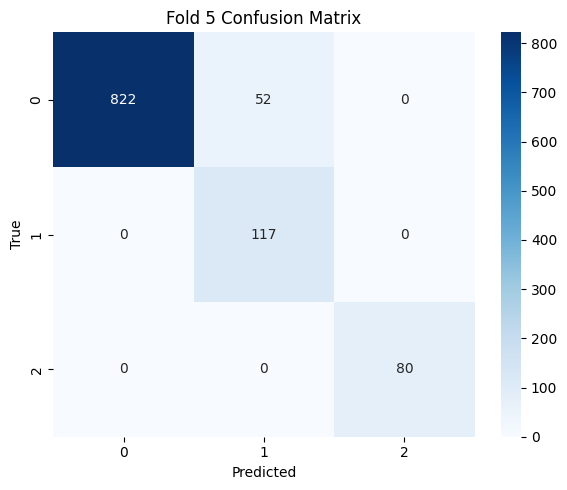


========== CV Results ==========
Mean Accuracy: 0.9817 ±(std_dev) 0.0165
Mean Macro F1: 0.9717 ±(std dev) 0.0235
Evaluation on 30% test data -

Test Accuracy: 0.9856 


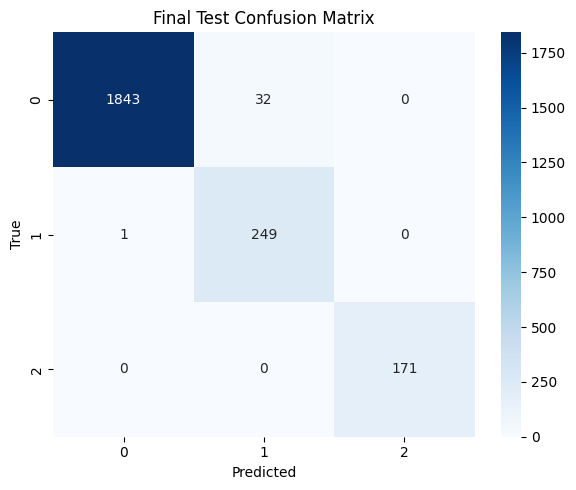


Evaluation Accuracy: 0.9865 


In [ ]:
# =============================== FULL CODE ===============================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix

from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------
# 1. Preprocessing Function
# ------------------------------
def preprocess_dataframe(df):
    if df.isnull().sum().sum() > 0:
        df.fillna(df.median(), inplace=True)

    pir_cols = [col for col in df.columns if 'PIR' in col.upper()]
    df['PIR_mean'] = df[pir_cols].mean(axis=1)
    df['PIR_std'] = df[pir_cols].std(axis=1)
    df['PIR_max'] = df[pir_cols].max(axis=1)
    df['PIR_min'] = df[pir_cols].min(axis=1)
    df['PIR_range'] = df['PIR_max'] - df['PIR_min']
    df['PIR_sum'] = df[pir_cols].sum(axis=1)
    df['PIR_median'] = df[pir_cols].median(axis=1)
    df['PIR_variance'] = df[pir_cols].var(axis=1)

    df = df.drop(columns=["Date", "Time"])
    X = df.drop(columns=["Label"])
    y = df["Label"]

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    return X_scaled, y_encoded, scaler, le

# ------------------------------
# 2. Load & Split Dataset
# ------------------------------
datafile = "pirvision_office_dataset1.csv"
df = pd.read_csv(datafile)
X_scaled, y_encoded, scaler, le = preprocess_dataframe(df)
num_classes = len(np.unique(y_encoded))

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.3, stratify=y_encoded, random_state=42
)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# ------------------------------
# 3. LSTM Model
# ------------------------------
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(LSTMClassifier, self).__init__()
        self.lstm = nn.LSTM(input_dim, 128, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc1 = nn.Linear(128, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = lstm_out[:, -1, :]
        out = self.dropout(out)
        out = self.fc1(out)
        out = torch.relu(out)
        out = self.fc2(out)
        return out

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

# ------------------------------
# 4. Training & Evaluation
# ------------------------------
def calculate_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    precision = []
    recall = []
    f1 = []
    for i in range(len(cm)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1_score = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
        precision.append(prec)
        recall.append(rec)
        f1.append(f1_score)
    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)
    return macro_precision, macro_recall, macro_f1, precision, recall, f1

def train_one_epoch(model, loader, criterion, optimizer, clip_value=5.0):
    model.train()
    running_loss = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip_value)
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
    return running_loss / len(loader.dataset)

def evaluate_model_internal(model, loader, criterion):
    model.eval()
    running_loss = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = criterion(preds, yb)
            running_loss += loss.item() * xb.size(0)
            all_preds.append(torch.argmax(preds, dim=1).cpu().numpy())
            all_labels.append(yb.cpu().numpy())
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    acc = accuracy_score(all_labels, all_preds)
    macro_precision, macro_recall, macro_f1, precision, recall, f1 = calculate_metrics(all_labels, all_preds)
    return running_loss / len(loader.dataset), acc, macro_f1, all_preds, all_labels, precision, recall, f1

def train_model_fixed_epochs(model, train_loader, val_loader, criterion, optimizer, max_epochs=30):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(max_epochs):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _, _, _, _, _ = evaluate_model_internal(model, val_loader, criterion)
        _, train_acc, _, _, _, _, _, _ = evaluate_model_internal(model, train_loader, criterion)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
    return model, history

# ------------------------------
# 5. 5-Fold Cross Validation
# ------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold = 1
acc_list, macro_f1_list = [], []
best_model_state = None
best_fold_accuracy = 0

for train_index, val_index in skf.split(X_train_full, y_train_full):
    print(f"\n=== Fold {fold} ===")
    X_train = X_train_full[train_index]
    y_train = y_train_full[train_index]
    X_val = X_train_full[val_index]
    y_val = y_train_full[val_index]

    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

    X_train_res = torch.tensor(X_train_res, dtype=torch.float32).unsqueeze(1)
    y_train_res = torch.tensor(y_train_res, dtype=torch.long)
    X_val = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
    y_val = torch.tensor(y_val, dtype=torch.long)

    train_loader = DataLoader(TensorDataset(X_train_res, y_train_res), batch_size=32, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64)

    model = LSTMClassifier(input_dim=X_train.shape[1], num_classes=num_classes).to(device)
    model.apply(init_weights)
    optimizer = optim.Adam(model.parameters(), lr=0.0005)
    criterion = nn.CrossEntropyLoss()

    model, history = train_model_fixed_epochs(model, train_loader, val_loader, criterion, optimizer)

    # Plots
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history['train_acc'], label="Train Accuracy")
    plt.plot(history['val_acc'], label="Validation Accuracy")
    plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.title(f"Fold {fold} - Accuracy")

    plt.subplot(1, 2, 2)
    plt.plot(history['train_loss'], label="Train Loss")
    plt.plot(history['val_loss'], label="Validation Loss")
    plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.title(f"Fold {fold} - Loss")
    plt.tight_layout(); plt.show()

    _, val_acc, val_macro_f1, val_preds, val_true, precision, recall, f1 = evaluate_model_internal(model, val_loader, criterion)
    print(f"Fold {fold} Accuracy: {val_acc:.4f} | Macro F1: {val_macro_f1:.4f}\n")

    for i, (p, r, f) in enumerate(zip(precision, recall, f1)):
          print(f"Class {i if i != 2 else 3} -> Precision: {p:.4f}, Recall: {r:.4f}, F1: {f:.4f}")


    cm = confusion_matrix(val_true, val_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Fold {fold} Confusion Matrix")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout(); plt.show()

    acc_list.append(val_acc)
    macro_f1_list.append(val_macro_f1)
    if val_acc > best_fold_accuracy:
        best_fold_accuracy = val_acc
        best_model_state = model.state_dict()
    fold += 1

print("\n========== CV Results ==========")
print(f"Mean Accuracy: {np.mean(acc_list):.4f} ±(std_dev) {np.std(acc_list):.4f}")
print(f"Mean Macro F1: {np.mean(macro_f1_list):.4f} ±(std dev) {np.std(macro_f1_list):.4f}")

# ------------------------------
# 6. Final Training
# ------------------------------
X_train_res_full, y_train_res_full = SMOTE(random_state=42).fit_resample(X_train_full, y_train_full)
X_train_tensor = torch.tensor(X_train_res_full, dtype=torch.float32).unsqueeze(1)
y_train_tensor = torch.tensor(y_train_res_full, dtype=torch.long)

final_model = LSTMClassifier(input_dim=X_train_full.shape[1], num_classes=num_classes).to(device)
final_model.load_state_dict(best_model_state)

train_loader_final = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=32, shuffle=True)
final_criterion = nn.CrossEntropyLoss()
final_optimizer = optim.Adam(final_model.parameters(), lr=0.0005)
final_model, history = train_model_fixed_epochs(final_model, train_loader_final, val_loader, final_criterion, final_optimizer)

final_checkpoint_path =  "best_final_model_lstm.pt"
torch.save(final_model.state_dict(), final_checkpoint_path)

# ------------------------------
# 7. Test Evaluation
# ------------------------------
X_test_reshaped = X_test_tensor.unsqueeze(1).to(device)
test_loader = DataLoader(TensorDataset(X_test_reshaped, y_test_tensor), batch_size=64)

final_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds = final_model(xb)
        all_preds.extend(torch.argmax(preds, dim=1).cpu().numpy())
        all_labels.extend(yb.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
#macro_precision, macro_recall, macro_f1, precision, recall, f1 = calculate_metrics(all_labels, all_preds)
print("Evaluation on 30% test data -")
print(f"\nTest Accuracy: {acc:.4f} ")#| Macro F1: {macro_f1:.4f}")


cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

# ------------------------------
# 8. Evaluation Function
# ------------------------------
def evaluate_model(datafile_location, checkpoint):
    df_test = pd.read_csv(datafile_location)
    X_scaled_test, y_encoded_test, _, _ = preprocess_dataframe(df_test)
    X_tensor = torch.tensor(X_scaled_test, dtype=torch.float32).unsqueeze(1)
    y_tensor = torch.tensor(y_encoded_test, dtype=torch.long)
    test_loader = DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=64)

    model = LSTMClassifier(input_dim=X_scaled_test.shape[1], num_classes=len(np.unique(y_encoded_test))).to(device)
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            preds = model(xb.to(device))
            all_preds.extend(torch.argmax(preds, dim=1).cpu().numpy())
            all_labels.extend(yb.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    macro_precision, macro_recall, macro_f1, precision, recall, f1 = calculate_metrics(all_labels, all_preds)

    print(f"\nEvaluation Accuracy: {acc:.4f} ")

    return acc

# Example usage:
eva_acc=evaluate_model("/content/pirvision_office_dataset1.csv", "best_final_model_lstm.pt")



=== Fold 1 ===
Early stopping triggered.
Fold 1 Accuracy: 0.9804 | Macro F1: 0.9681
Class 0: Precision=0.9988, Recall=0.9771, F1=0.9879
Class 1: Precision=0.8519, Recall=0.9914, F1=0.9163
Class 3: Precision=1.0000, Recall=1.0000, F1=1.0000


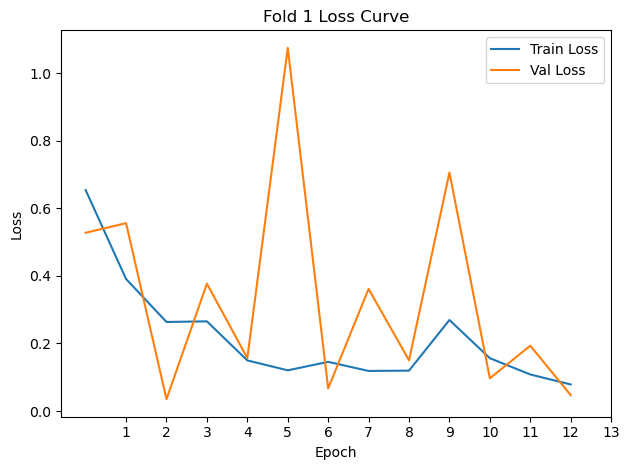

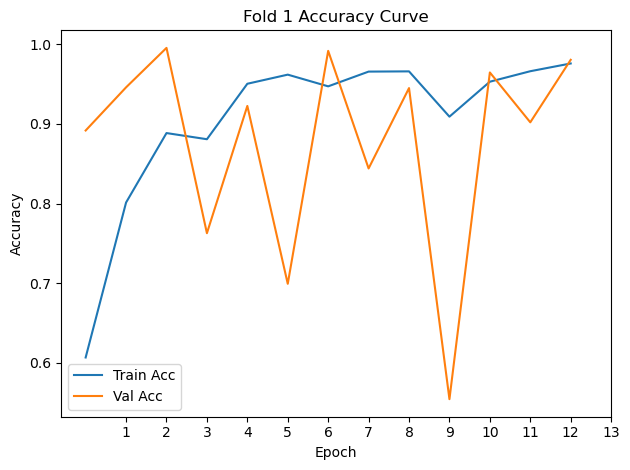

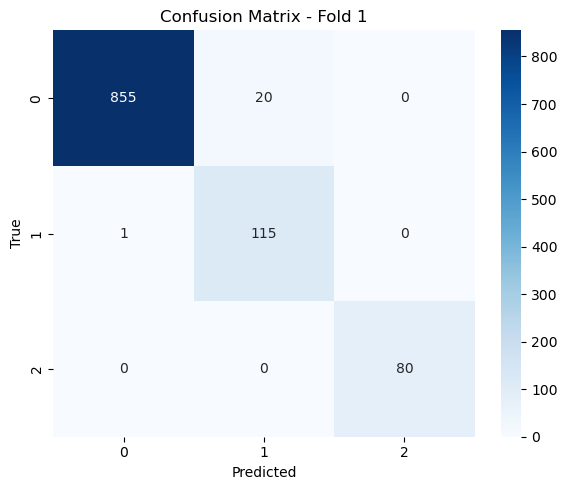


=== Fold 2 ===
Early stopping triggered.
Fold 2 Accuracy: 0.9869 | Macro F1: 0.9782
Class 0: Precision=0.9988, Recall=0.9851, F1=0.9919
Class 1: Precision=0.8984, Recall=0.9914, F1=0.9426
Class 3: Precision=1.0000, Recall=1.0000, F1=1.0000


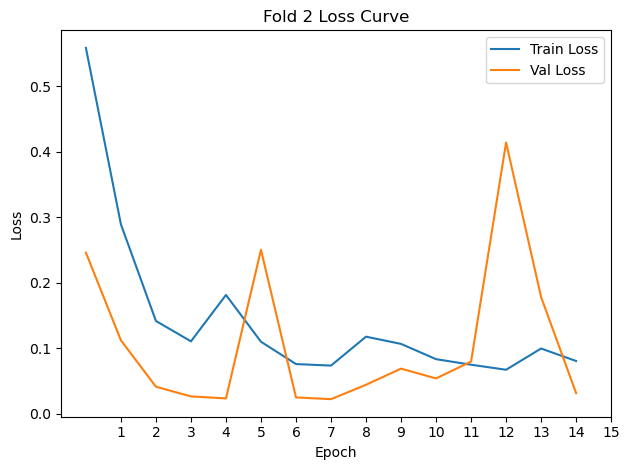

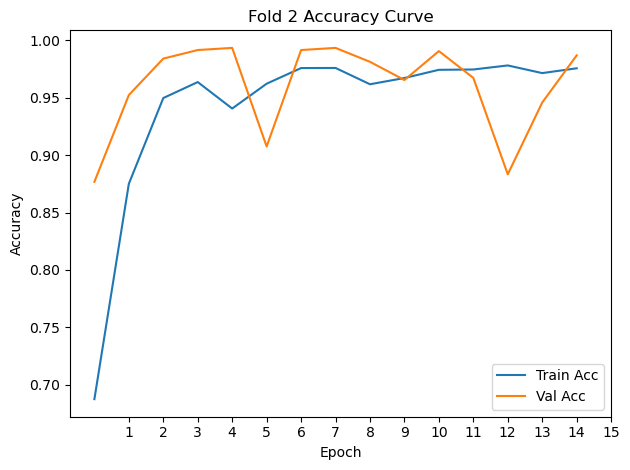

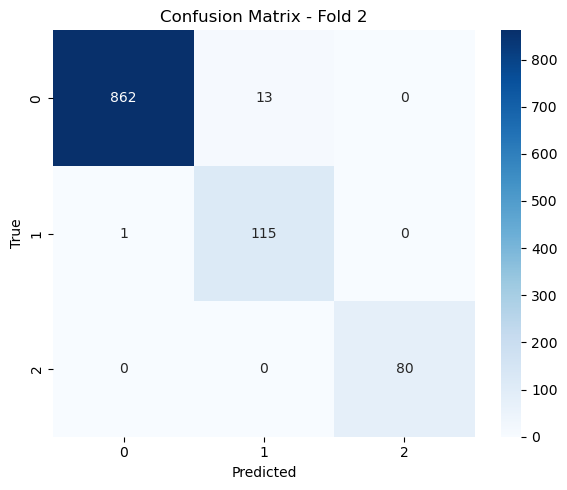


=== Fold 3 ===
Early stopping triggered.
Fold 3 Accuracy: 0.9776 | Macro F1: 0.9644
Class 0: Precision=1.0000, Recall=0.9725, F1=0.9861
Class 1: Precision=0.8298, Recall=1.0000, F1=0.9070
Class 3: Precision=1.0000, Recall=1.0000, F1=1.0000


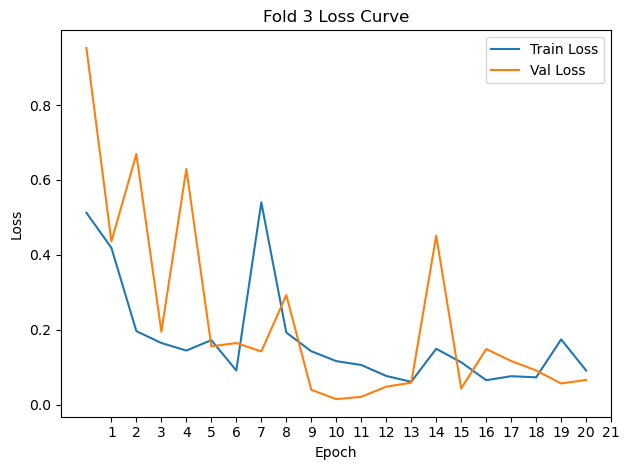

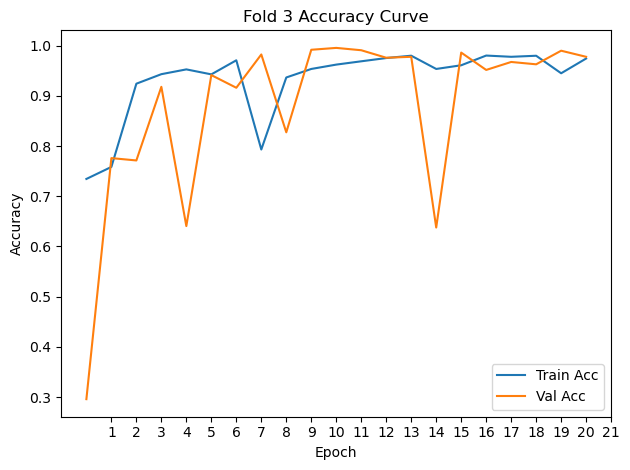

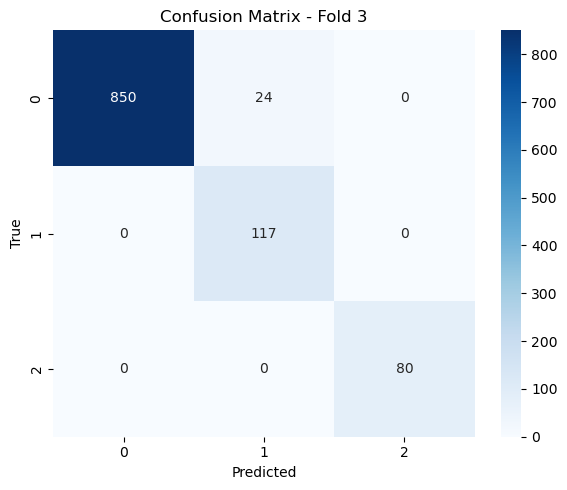


=== Fold 4 ===
Early stopping triggered.
Fold 4 Accuracy: 0.9561 | Macro F1: 0.9092
Class 0: Precision=0.9509, Recall=0.9977, F1=0.9738
Class 1: Precision=0.9730, Recall=0.6154, F1=0.7539
Class 3: Precision=1.0000, Recall=1.0000, F1=1.0000


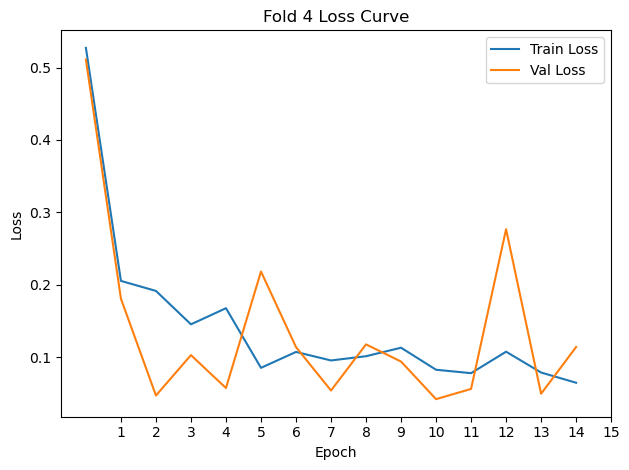

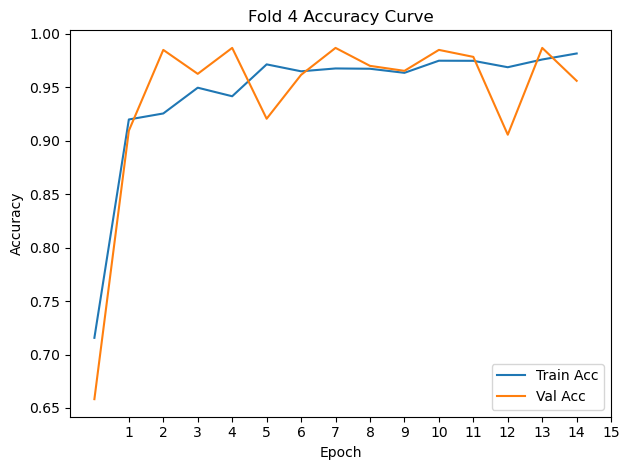

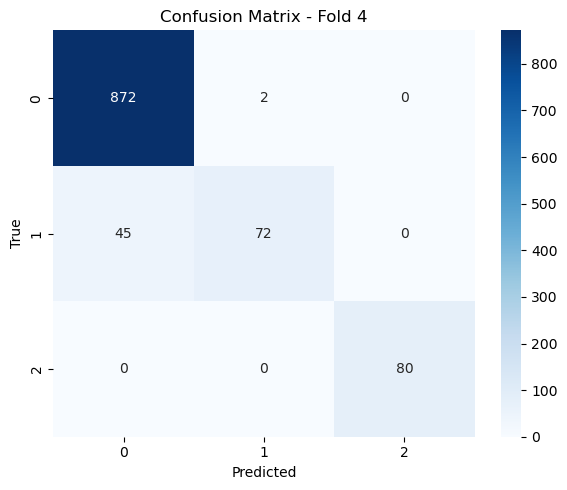


=== Fold 5 ===
Early stopping triggered.
Fold 5 Accuracy: 0.9907 | Macro F1: 0.9842
Class 0: Precision=0.9977, Recall=0.9908, F1=0.9943
Class 1: Precision=0.9350, Recall=0.9829, F1=0.9583
Class 3: Precision=1.0000, Recall=1.0000, F1=1.0000


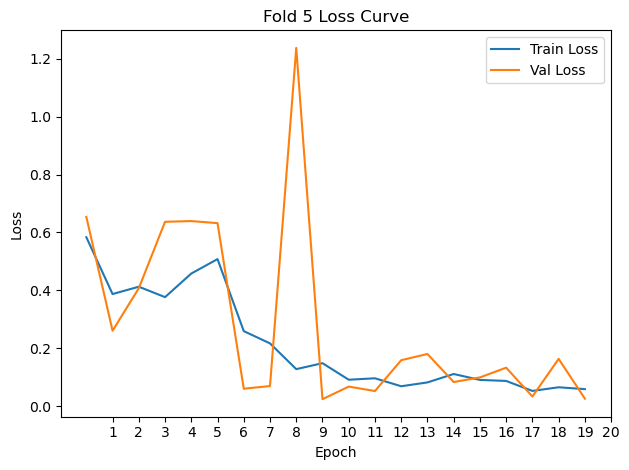

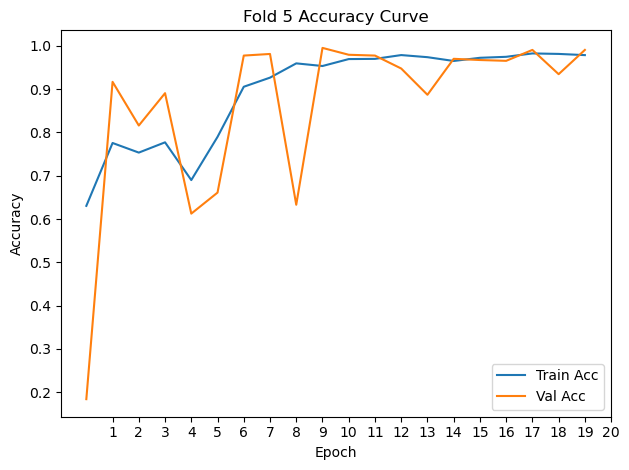

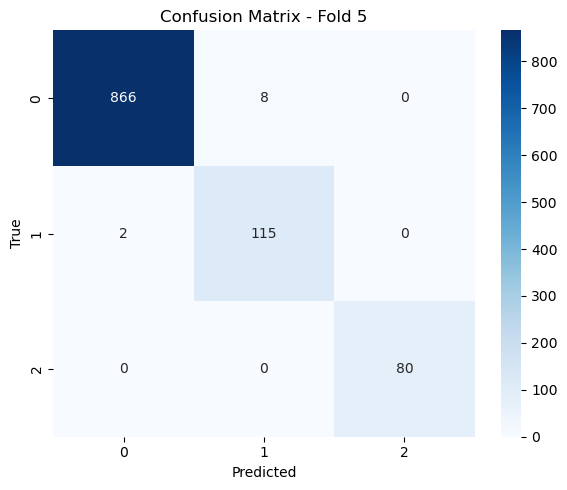


=== CV Results ===
Mean Accuracy: 0.9783 (Std: 0.0120)
Mean Macro F1: 0.9608 (Std: 0.0267)

=== Retraining on the complete 70% training dataset using best CV model parameters ===
Early stopping triggered.

Test Accuracy (Retrained Model): 0.9747


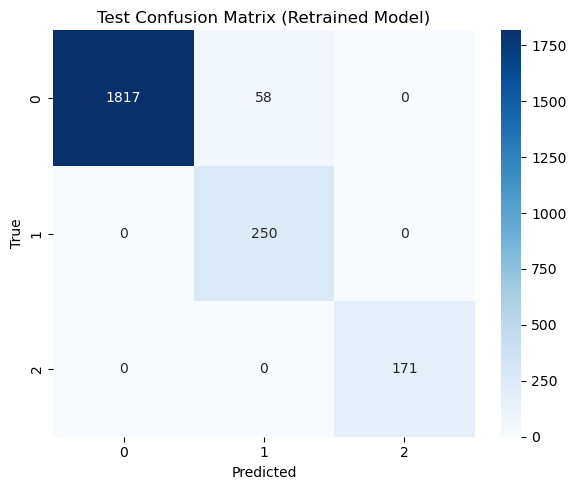


Evaluation function accuracy (Retrained Model): 0.9781727878708666


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --------------------- Preprocessing Function ---------------------
def preprocess_dataframe(df):
    if df.isnull().sum().sum() > 0:
        df.fillna(df.median(), inplace=True)
    pir_cols = [col for col in df.columns if 'PIR' in col.upper()]
    df["PIR_mean"] = df[pir_cols].mean(axis=1)
    df["PIR_std"] = df[pir_cols].std(axis=1)
    df["PIR_max"] = df[pir_cols].max(axis=1)
    df["PIR_min"] = df[pir_cols].min(axis=1)
    df["PIR_range"] = df["PIR_max"] - df["PIR_min"]
    df["PIR_sum"] = df[pir_cols].sum(axis=1)
    df["PIR_median"] = df[pir_cols].median(axis=1)
    df["PIR_variance"] = df[pir_cols].var(axis=1)
    df.drop(columns=["Date", "Time"], inplace=True)
    X = df.drop(columns=["Label"])
    y = df["Label"]
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    return X_scaled, y_encoded, scaler, le

# --------------------- Positional Encoding ---------------------
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

# --------------------- Transformer Classifier ---------------------
class TransformerClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, embed_dim=128, num_heads=4, ff_dim=256, dropout=0.2):
        super().__init__()
        self.embed = nn.Linear(input_dim, embed_dim)
        self.pos_encoder = PositionalEncoding(embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                                   dim_feedforward=ff_dim, dropout=dropout,
                                                   batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.embed(x)
        x = self.pos_encoder(x)
        x = self.transformer(x)
        x = x.transpose(1, 2)
        x = self.pool(x).squeeze(-1)
        return self.classifier(x)

# --------------------- Weight Initialization ---------------------
def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

# --------------------- Training Function ---------------------
def train_model(model, loader, vloader, criterion, optimizer, epochs=30, patience=10):
    best_acc = 0
    best_weights = None
    no_improve = 0
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device).float(), yb.to(device)
            optimizer.zero_grad()
            output = model(xb)
            loss = criterion(output, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * yb.size(0)
            correct += (output.argmax(1) == yb).sum().item()
            total += yb.size(0)
        train_loss = running_loss / total
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in vloader:
                xb, yb = xb.to(device).float(), yb.to(device)
                output = model(xb)
                loss = criterion(output, yb)
                val_loss += loss.item() * yb.size(0)
                val_correct += (output.argmax(1) == yb).sum().item()
                val_total += yb.size(0)
        val_loss /= val_total
        val_acc = val_correct / val_total
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_weights = model.state_dict()
            no_improve = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            print("Early stopping triggered.")
            break
    model.load_state_dict(best_weights)
    return model, train_losses, val_losses, train_accs, val_accs

# --------------------- Dataset Loading ---------------------
df = pd.read_csv("Dataset/pirvision_fog_presence_detection/pirvision_office_dataset1.csv")
X_scaled, y_encoded, scaler, le = preprocess_dataframe(df)
num_classes = len(np.unique(y_encoded))
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.3, stratify=y_encoded, random_state=42)

# --------------------- Cross-Validation ---------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
accs, f1s = [], []
best_model_state = None
best_fold_acc = 0
fold = 1

for train_idx, val_idx in skf.split(X_train_full, y_train_full):
    print(f"\n=== Fold {fold} ===")
    X_train, X_val = X_train_full[train_idx], X_train_full[val_idx]
    y_train, y_val = y_train_full[train_idx], y_train_full[val_idx]

    # Apply SMOTE to oversample the fold training data
    X_train_res, y_train_res = SMOTE(random_state=42).fit_resample(X_train, y_train)

    # No class weights, so simply define the loss function.
    criterion = nn.CrossEntropyLoss()

    # Create TensorDatasets for training and validation (with sequence dimension)
    train_ds = TensorDataset(torch.tensor(X_train_res).float().unsqueeze(1), torch.tensor(y_train_res))
    val_ds = TensorDataset(torch.tensor(X_val).float().unsqueeze(1), torch.tensor(y_val))
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=64)

    model = TransformerClassifier(input_dim=X_scaled.shape[1], num_classes=num_classes).to(device)
    model.apply(init_weights)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    model, train_losses, val_losses, train_accs, val_accs = train_model(model, train_loader, val_loader, criterion, optimizer)

    # Evaluate on the validation set for the fold
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device).float()
            out = model(xb)
            y_true.extend(yb.numpy())
            y_pred.extend(torch.argmax(out, axis=1).cpu().numpy())

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"Fold {fold} Accuracy: {acc:.4f} | Macro F1: {f1:.4f}")
    accs.append(acc)
    f1s.append(f1)

    # Print per-class metrics using original labels
    precision, recall, f1_class, _ = precision_recall_fscore_support(y_true, y_pred, labels=np.unique(y_true))
    for idx, (p, r, f) in enumerate(zip(precision, recall, f1_class)):
        original_class = le.inverse_transform([idx])[0]
        print(f"Class {original_class}: Precision={p:.4f}, Recall={r:.4f}, F1={f:.4f}")

    # Plot Loss curves (with integer epoch ticks)
    plt.figure()
    plt.plot(train_losses, label="Train Loss")
    plt.plot(val_losses, label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Fold {fold} Loss Curve")
    plt.legend()
    epochs_ticks = list(range(1, len(train_losses) + 1))
    plt.xticks(epochs_ticks)
    plt.tight_layout()
    plt.show()

    # Plot Accuracy curves (with integer epoch ticks)
    plt.figure()
    plt.plot(train_accs, label="Train Acc")
    plt.plot(val_accs, label="Val Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Fold {fold} Accuracy Curve")
    plt.legend()
    epochs_ticks = list(range(1, len(train_accs) + 1))
    plt.xticks(epochs_ticks)
    plt.tight_layout()
    plt.show()

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
    plt.title(f"Confusion Matrix - Fold {fold}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

    if acc > best_fold_acc:
        best_fold_acc = acc
        best_model_state = model.state_dict()

    fold += 1

# --------------------- CV Summary ---------------------
print("\n=== CV Results ===")
print(f"Mean Accuracy: {np.mean(accs):.4f} (Std: {np.std(accs):.4f})")
print(f"Mean Macro F1: {np.mean(f1s):.4f} (Std: {np.std(f1s):.4f})")

# --------------------- Retraining on Entire 70% Training Data ---------------------
print("\n=== Retraining on the complete 70% training dataset using best CV model parameters ===")
# Use SMOTE on the full training set
X_train_res, y_train_res = SMOTE(random_state=42).fit_resample(X_train_full, y_train_full)
criterion = nn.CrossEntropyLoss()  # No class weights

# Create DataLoader for the full training set (with sequence dimension)
train_ds_full = TensorDataset(torch.tensor(X_train_res).float().unsqueeze(1), torch.tensor(y_train_res))
train_loader_full = DataLoader(train_ds_full, batch_size=32, shuffle=True)

# Initialize the retraining model and load best CV parameters
model_retrained = TransformerClassifier(input_dim=X_scaled.shape[1], num_classes=num_classes).to(device)
model_retrained.load_state_dict(best_model_state)

optimizer = optim.Adam(model_retrained.parameters(), lr=0.001)
# Here, for retraining, the same loader is used as both train & validation
model_retrained, train_losses_full, _, train_accs_full, _ = train_model(
    model_retrained, train_loader_full, train_loader_full, criterion, optimizer, epochs=30, patience=10
)

# Save the retrained model as the final checkpoint
final_checkpoint_path = os.path.join("checkpoints", "best_final_model_tf.pt")
os.makedirs(os.path.dirname(final_checkpoint_path), exist_ok=True)
torch.save(model_retrained.state_dict(), final_checkpoint_path)

# --------------------- Final Test Set Evaluation (with retrained model) ---------------------
model_retrained.eval()
X_test_tensor = torch.tensor(X_test).float().unsqueeze(1).to(device)
with torch.no_grad():
    test_preds = model_retrained(X_test_tensor).argmax(axis=1).cpu().numpy()

test_acc = accuracy_score(y_test, test_preds)
print(f"\nTest Accuracy (Retrained Model): {test_acc:.4f}")

cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.title("Test Confusion Matrix (Retrained Model)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# --------------------- Evaluation Function ---------------------
def evaluate_model(datafile_location, checkpoint):
    """
    Evaluate a pretrained Transformer model on a dataset located at datafile_location.

    This function reads the dataset, preprocesses it using preprocess_dataframe(),
    loads the saved model checkpoint, and computes accuracy on the test data.

    Parameters:
        datafile_location (str): Path to the CSV file containing test data.
        checkpoint (str): Path to the saved model checkpoint.

    Returns:
        test_acc (float): Accuracy of the model on the test dataset.
    """
    df_eval = pd.read_csv(datafile_location)
    X_scaled_eval, y_encoded_eval, scaler_eval, le_eval = preprocess_dataframe(df_eval)
    X_tensor = torch.tensor(X_scaled_eval).float().unsqueeze(1)
    y_tensor = torch.tensor(y_encoded_eval)
    eval_ds = TensorDataset(X_tensor, y_tensor)
    eval_loader = DataLoader(eval_ds, batch_size=64)

    input_dim = X_scaled_eval.shape[1]
    model = TransformerClassifier(input_dim=input_dim, num_classes=len(np.unique(y_encoded_eval))).to(device)
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    model.eval()

    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in eval_loader:
            xb, yb = xb.to(device).float(), yb.to(device)
            preds = model(xb)
            y_true.extend(yb.cpu().numpy())
            y_pred.extend(torch.argmax(preds, axis=1).cpu().numpy())

    test_acc = accuracy_score(y_true, y_pred)
    return test_acc

# Example usage of evaluate_model:
checkpoint_path = final_checkpoint_path  # Retrained model checkpoint
test_file_location = "Dataset/pirvision_fog_presence_detection/pirvision_office_dataset1.csv"
eval_accuracy = evaluate_model(test_file_location, checkpoint_path)
print("\nEvaluation function accuracy (Retrained Model):", eval_accuracy)